# 3. Retrieval evaluation: Development integration under the frozen v3 protocol

## 1. Which models, rankings and references are being evaluated?

The preceding notebook validated `benchmark-freeze-v1` under `benchmark-design-v3`.
This notebook verifies the complete analysis pipeline on **Development data only**:
stored ten-image pilot rankings plus controlled arithmetic examples. It does not
encode images, request downloads or rank the 871 frozen Test images.

Sections 2–6 retain historical pilot measurements and qualitative Development
inspection; sections 7–11 demonstrate the new frozen completion/aggregation
contracts. References enter after ranking, and generalized map agreement remains
distinct from independently verified visible truth. Final evaluation awaits human
merge of WP5 and completion of Review 2.

In [1]:
import json
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display

from earth_observation.analysis_protocol import load_frozen_benchmark
from earth_observation.encoding import file_digest, model_rgb
from earth_observation.evaluation_run import (
    evaluate_development,
    load_development_pilot,
)
from earth_observation.raster import RGB_BANDS, patch_files, read_rgb_bands
from earth_observation.reference import evaluate_pilot, load_specifications

# Optional progress widgets are not needed for this stored-artifact analysis.
warnings.filterwarnings("ignore", message="IProgress not found.*")

# Configuration: Development only; no parameter selection from model results.
ROOT = Path.cwd().resolve()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
CONFIG_PATH = ROOT / "config/frozen-models-v1.json"
CONFIG = json.loads(CONFIG_PATH.read_text())
EXAMPLE_QUERIES = ["single-arable-land/p1", "adjacent-forest-water/p1"]
MODEL_NAMES = {"clip-openai-vit-b32": "CLIP", "remoteclip-vit-b32": "RemoteCLIP"}
MODEL_COLORS = {"clip-openai-vit-b32": "#2166ac", "remoteclip-vit-b32": "#d6604d"}
OUTPUT = ROOT / "outputs" / CONFIG["version"]
plt.rcParams["figure.dpi"] = 80
display(pd.DataFrame(CONFIG["models"])[["model_id", "size_bytes", "sha256"]])
display(pd.Series(CONFIG["runtime"], name="runtime"))
FREEZE_PATH = ROOT / "manifests/benchmark-freeze-v1.json"
PROTOCOL_PATH = ROOT / "config/analysis-protocol-v1.json"
DESIGN_PATH = ROOT / "config/benchmark-design-v3.json"

,model_id,size_bytes,sha256
0,clip-openai-vit-b32,353976522,40d365715913c9da98579312b702a82c18be219cc2a734...
1,remoteclip-vit-b32,605208421,60014e395d930a3f2963d1d89c8522bf4ad56775571e43...


device               cpu
precision        float32
torch_threads          4
batch_size             5
seed                   0
Name: runtime, dtype: object

## 2. How do measurements become embeddings and rankings?

Raw B04/B03/B02 values become RGB uint8 using
$\operatorname{round}_{\mathrm{even}}(255\,\operatorname{clip}(DN/3000,0,1))$.
This is an explicit, versioned development input decision, not calibrated reflectance
and not an implicit call to the display helper. Any masked or nonfinite RGB pixel
rejects the input; the current thirty bands have no masked pixels. No map-based
mask is applied. Checkpoint preprocessing then resizes the shortest edge to 224
with bicubic interpolation, takes a central 224 × 224 crop, converts to a tensor
and uses CLIP's channel means and standard deviations. Text uses CLIP byte-pair
tokenization with BOS/EOS and a 77-token context; overlong text fails rather than
being silently truncated.

For image embedding $v_i$ and text embedding $t_q$, unit normalization yields
$\hat v_i=v_i/\|v_i\|_2$ and $\hat t_q=t_q/\|t_q\|_2$. The score is
$S_{qi}=\hat t_q^\mathsf{T}\hat v_i$: cosine similarity, **not a probability**.
All 24 × 10 scores per model are computed directly. Ties use ascending full patch
ID. Maps first enter after ranking, to attach reference states.

The cache identifies checkpoint, architecture, RGB conversion, checkpoint
preprocessing, tokenizer bytes, software and source versions, ordered image bytes,
and ordered query IDs/texts. Cached float32 unit vectors carry shape and byte-digest
checks. A cache hit does not instantiate or run the model. The table below distinguishes
original measured encoding times from this notebook's cached execution.

In [2]:
frozen_record = load_frozen_benchmark(FREEZE_PATH, ROOT)
metrics, rankings, provenance = load_development_pilot(ROOT, frozen_record)
runtime_rows = []
for model_id, run in provenance["models"].items():
    original = run["original_encoding"]
    assert original["evaluation_mode"] and original["all_parameters_frozen"]
    runtime_rows.append(
        {
            "model": MODEL_NAMES[model_id],
            "load_s_original": original["load_seconds"],
            "images_s_original": original["image_encoding_seconds"],
            "texts_s_original": original["text_encoding_seconds"],
        }
    )
display(pd.DataFrame(runtime_rows).round(4))
display(pd.Series(provenance["platform"], name="historical_encoding_runtime"))
print(f"Loaded {len(metrics)} stored formulation results; {len(rankings)} ranked rows.")
print("Freeze validated; original model/cache identities verified; no new encoding.")

,model,load_s_original,images_s_original,texts_s_original
0,CLIP,1.6570,0.2046,0.9478
1,RemoteCLIP,1.8004,0.1800,0.9608


machine      arm64
python     3.12.12
system      Darwin
Name: historical_encoding_runtime, dtype: object

Loaded 48 stored formulation results; 480 ranked rows.
Freeze validated; original model/cache identities verified; no new encoding.


### 2.1 Can the stored Development artifacts be read without changing caches?

Metric source changes are separate from the original embedding identities, which
also pinned the historical ranking module. We verify those immutable caches and
stored result hashes explicitly; we do not regenerate cache keys, encode again,
or silently relabel historical encoding provenance as the current implementation.

In [3]:
cache_files = [
    ROOT / "data/cache/embeddings" / f"{run['cache_key']}.npz"
    for run in provenance["models"].values()
]
mtimes = [path.stat().st_mtime_ns for path in cache_files]
reused_metrics, reused_rankings, reused_provenance = load_development_pilot(
    ROOT, frozen_record
)
assert mtimes == [path.stat().st_mtime_ns for path in cache_files]
pd.testing.assert_frame_equal(metrics, reused_metrics)
pd.testing.assert_frame_equal(rankings, reused_rankings)
print(
    "Both embedding caches reused; no encoding; unchanged files and identical results."
)

Both embedding caches reused; no encoding; unchanged files and identical results.


## 3. What did the historical fully judged pilot metrics measure?

What do P@10 and average precision measure?

For fully judged candidates, let $r_j\in\{0,1\}$ indicate map relevance at rank
$j$, and $R=\sum_{j=1}^{N}r_j$. We define

$$P@10=\frac{1}{10}\sum_{j=1}^{10}r_j,\qquad
AP=\frac{1}{R}\sum_{j=1}^{N}r_j\frac{\sum_{\ell=1}^{j}r_\ell}{j}.$$

AP averages precision at relevant ranks and rewards earlier relevant images.
P@10 is undefined with fewer than ten candidates. AP is undefined with zero
positives; P@10 is zero for ten or more fully judged negative candidates. Any
unknown reference makes the main metrics undefined under our conservative policy.
We retain counts and judged coverage. Separately named `judged_only_*` diagnostics
remove unknowns from the already fixed ranking; diagnostic precision divides by
min(10, judged count). These are not unrestricted main retrieval metrics.

With **exactly ten candidates**, P@10 equals reference prevalence and cannot
measure ranking quality. All candidates here are judged; forest AP = 1 is also
uninformative because all ten patches are forest-positive. No intent aggregation
or statistical interval is computed.

In [4]:
first_formulation = metrics[metrics.query_id.str.endswith("/p1")]
ap_table = first_formulation.pivot(
    index="intent_id", columns="model_id", values="average_precision"
).rename(columns=MODEL_NAMES)
coverage = first_formulation[
    first_formulation.model_id == "clip-openai-vit-b32"
].set_index("intent_id")
display(
    coverage[["candidate_count", "known_positive_count", "unknown_count", "p_at_10"]]
    .join(ap_table)
    .round(4)
)

,candidate_count,known_positive_count,unknown_count,p_at_10,CLIP,RemoteCLIP
intent_id,,,,,,
single-forest,10,10,0,1.0,1.0000,1.0000
single-inland-water,10,6,0,0.6,0.6607,0.8179
single-arable-land,10,3,0,0.3,0.8095,0.3417
single-pasture,10,5,0,0.5,0.4635,0.5976
both-forest-water,10,6,0,0.6,0.7440,0.8179
adjacent-forest-water,10,6,0,0.6,0.6357,0.7345
both-arable-pasture,10,2,0,0.2,0.4167,0.2500
adjacent-arable-pasture,10,2,0,0.2,0.3667,0.2083


## 4. How do individual formulations behave?

The first-formulation table is a display slice, not an average across paraphrases.
For example, CLIP has AP 0.8095 and RemoteCLIP 0.3417 for the first arable-land
formulation; for the first inland-water formulation their AP values are 0.6607
and 0.8179. This motivates inspecting ranks, not declaring an overall winner.
The complete table below keeps all formulations separate. Query wording and
reference thresholds were inherited unchanged, not selected from these scores.

In [5]:
display(
    metrics.pivot(index="query_id", columns="model_id", values="average_precision")
    .rename(columns=MODEL_NAMES)
    .round(4)
)

model_id,CLIP,RemoteCLIP
query_id,,
adjacent-arable-pasture/p1,0.3667,0.2083
adjacent-arable-pasture/p2,0.5000,0.2083
adjacent-arable-pasture/p3,0.4500,0.2250
adjacent-forest-water/p1,0.6357,0.7345
adjacent-forest-water/p2,0.8107,0.7028
adjacent-forest-water/p3,0.8375,0.8972
both-arable-pasture/p1,0.4167,0.2500
both-arable-pasture/p2,0.4167,0.2250
both-arable-pasture/p3,0.4500,0.2250


## 5. Which actual top images explain the scores?

Inspect the first three ranks for two fixed first formulations: arable land and
forest adjacent to inland water, for both models. Every row uses the same
unrestricted ten candidates. Titles show cosine similarity and the provisional
**map** decision. These labels are added after ranking and are not visually
verified truth. The displayed images use the explicit model RGB conversion before
checkpoint resizing. Brightness/color alone is not a land-cover reference.
No separate relation-control candidate set is tested in this package.

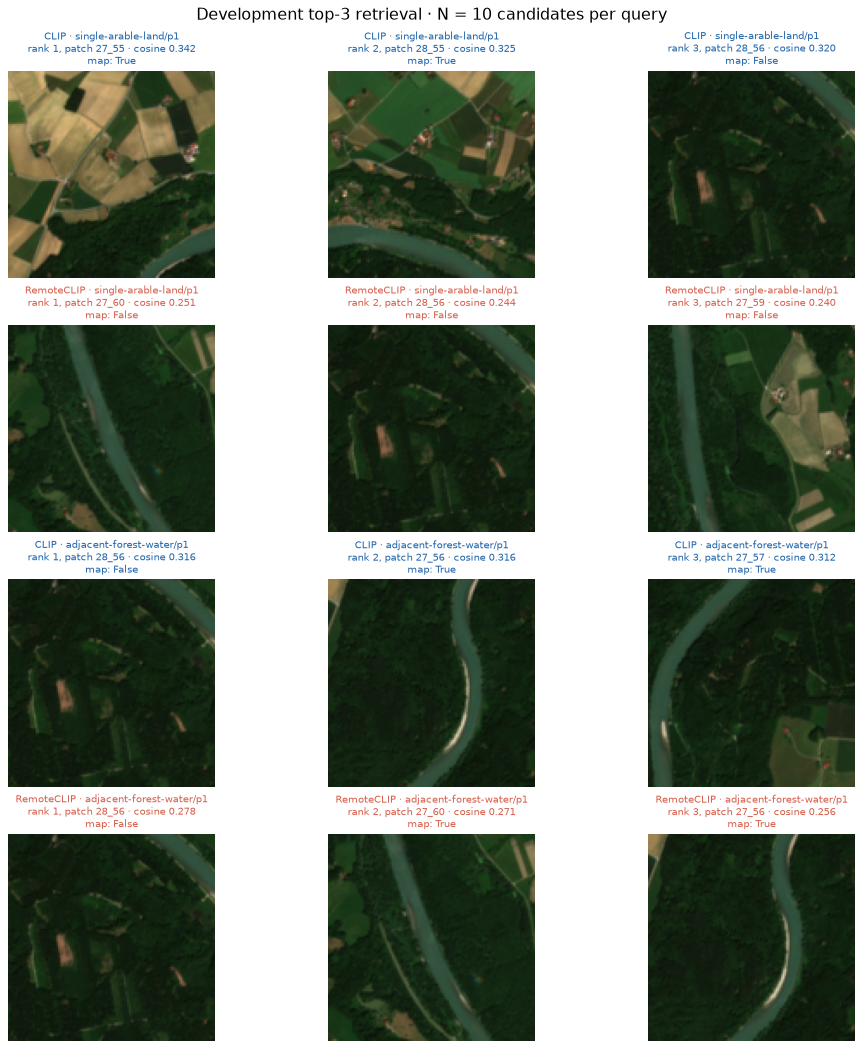

,model,query_id,rank,patch_suffix,map_state
0,CLIP,single-arable-land/p1,1,27_55,True
1,CLIP,single-arable-land/p1,2,28_55,True
2,CLIP,single-arable-land/p1,3,28_56,False
3,RemoteCLIP,single-arable-land/p1,1,27_60,False
4,RemoteCLIP,single-arable-land/p1,2,28_56,False
5,RemoteCLIP,single-arable-land/p1,3,27_59,False
6,CLIP,adjacent-forest-water/p1,1,28_56,False
7,CLIP,adjacent-forest-water/p1,2,27_56,True
8,CLIP,adjacent-forest-water/p1,3,27_57,True
9,RemoteCLIP,adjacent-forest-water/p1,1,28_56,False


In [6]:
fig, axes = plt.subplots(4, 3, figsize=(12, 13), constrained_layout=True)
example_table = []
row_number = 0
for query_id in EXAMPLE_QUERIES:
    for model_id in MODEL_NAMES:
        top = rankings[
            (rankings.query_id == query_id) & (rankings.model_id == model_id)
        ].head(3)
        for column, result in enumerate(top.itertuples()):
            paths = patch_files(
                result.patch_id,
                ROOT / "data/raw/BigEarthNet-S2",
                ROOT / "data/raw/Reference_Maps",
            )
            image = model_rgb(
                read_rgb_bands({b: paths[b] for b in RGB_BANDS}),
                CONFIG["rgb"]["upper_dn"],
            )
            axes[row_number, column].imshow(image)
            suffix = "_".join(result.patch_id.split("_")[-2:])
            axes[row_number, column].set_title(
                f"{MODEL_NAMES[model_id]} · {query_id}\n"
                f"rank {result.rank}, patch {suffix} · "
                f"cosine {result.cosine_similarity:.3f}\n"
                f"map: {result.reference_state}",
                color=MODEL_COLORS[model_id],
                fontsize=9,
            )
            axes[row_number, column].axis("off")
            example_table.append(
                {
                    "model": MODEL_NAMES[model_id],
                    "query_id": query_id,
                    "rank": result.rank,
                    "patch_suffix": suffix,
                    "map_state": result.reference_state,
                }
            )
        row_number += 1
fig.suptitle("Development top-3 retrieval · N = 10 candidates per query", fontsize=14)
figure_path = OUTPUT / "top_results.png"
fig.savefig(figure_path, dpi=140)
plt.show()
display(pd.DataFrame(example_table))

### 5.1 Why is the visually water-containing top result map-negative?

Both models rank patch `28_56` first for the illustrated forest/water adjacency
query. RGB inspection shows forest and a water strip. The native map has 4.53%
inland water, below the unchanged 5% presence threshold, despite 880 m of shared
forest/water boundary. The derived adjacency condition therefore fails its water
presence requirement. This is disagreement with the operational reference, not
proof that the natural-language spatial description is visually wrong. We retain
the rule and do not retune it from these model results.

In [7]:
rules, queries = load_specifications(
    ROOT / "config/reference-rules-v1.json", ROOT / "config/query-specification-v1.json"
)
summaries, _ = evaluate_pilot(
    ROOT / "manifests/data-pilot-v1.json",
    ROOT / "data/cache",
    ROOT / "data/raw",
    rules,
    queries,
)
patch_id = next(pid for pid in summaries if pid.endswith("_28_56"))
evidence = summaries[patch_id]
display(
    pd.Series(
        {
            "map_water_percent": 100
            * evidence["classes"]["inland_water"]["fraction_lower"],
            "required_water_percent": 100
            * rules["classes"]["inland_water"]["presence_fraction"],
            "map_forest_water_boundary_m": evidence["pairs"][
                ("forest", "inland_water")
            ]["boundary_lower_m"],
            "required_boundary_m": rules["adjacency"]["min_shared_boundary_m"],
        }
    ).round(4)
)

map_water_percent                4.5278
required_water_percent           5.0000
map_forest_water_boundary_m    880.0000
required_boundary_m             60.0000
dtype: float64

## 6. What did the historical pilot establish?

Both identified frozen models produced valid embeddings and deterministic
complete Development rankings; their original caches and measurements remain
unchanged. This spatially concentrated ten-image sample cannot establish
superiority, geographic robustness or isolated relation capability. At N=10,
P@10 is prevalence and every top-ten Jaccard equals one regardless of order.
The following sections implement the newly frozen analysis, not final Test
results. No threshold, query or reference is tuned using these pilot scores.

In [8]:
figure_provenance = {
    "experiment_version": CONFIG["version"],
    "example_queries": EXAMPLE_QUERIES,
    "figure_sha256": file_digest(figure_path),
    "ranking_sha256": reused_provenance["outputs"]["rankings.csv"],
    "embedding_cache_keys": [r["cache_key"] for r in provenance["models"].values()],
}
(OUTPUT / "top_results_provenance.json").write_text(
    json.dumps(figure_provenance, indent=2) + "\n"
)
print("Saved versioned development tables, run provenance and top-result figure.")

Saved versioned development tables, run provenance and top-result figure.


## 7. How does a fixed ranking yield reference-uncertainty bounds?

For one intent let $U$ be unknown patch IDs and $z\in\{0,1\}^{|U|}$ a binary
completion. Known labels stay fixed. $y_r(z)$ is completed relevance at rank $r$
and $R(z)=\sum_{r=1}^{N}y_r(z)$. No candidate is removed or reranked.

$$P@10(z)=\frac{1}{10}\sum_{r=1}^{10}y_r(z),\qquad
AP(z)=\frac{1}{R(z)}\sum_{r=1}^{N}y_r(z)
       \frac{\sum_{s=1}^{r}y_s(z)}{r}.$$

P@10 bounds are $[a/10,(a+b)/10]$ for $a$ known positives and $b$ unknowns
in the first ten. AP needs enumeration with its **variable positive denominator**.
Any possible $R=0$ blocks AP; N<10 makes P@10 undefined. Above twelve unknowns,
analysis is blocked rather than approximated. These intervals describe reference
uncertainty, not statistical confidence intervals.

The controlled ranking below is `[?, 0, 1, ?, 0, …, 0]` with twelve candidates.
It is an arithmetic test case, not a new image/reference annotation.

In [9]:
from earth_observation.retrieval import completion_metrics, ranking_metrics

protocol = json.loads(PROTOCOL_PATH.read_text())
toy_ids = [f"p{i:02}" for i in range(12)]
toy_states = ["unknown", "false", "true", "unknown"] + ["false"] * 8
toy_reference = dict(zip(toy_ids, toy_states, strict=True))
toy_metrics = completion_metrics(toy_ids, toy_reference, protocol)
display(
    pd.DataFrame(
        {
            "assignment (p00, p03)": ["(0,0)", "(0,1)", "(1,0)", "(1,1)"],
            "P@10": toy_metrics["values"]["p_at_10"],
            "AP": toy_metrics["values"]["average_precision"],
        }
    ).round(6)
)
display(
    pd.DataFrame(ranking_metrics(toy_ids, toy_reference, protocol)["metric_bounds"]).T
)
assert toy_metrics["values"]["average_precision"].max() > max(
    toy_metrics["values"]["average_precision"][[0, -1]]
)

,"assignment (p00, p03)",P@10,AP
0,"(0,0)",0.1,0.333333
1,"(0,1)",0.2,0.416667
2,"(1,0)",0.2,0.833333
3,"(1,1)",0.3,0.805556


,status,value,lower,upper,reason,uncertainty_type
p_at_10,reference-uncertainty-interval,None,0.1,0.3,None,reference
average_precision,reference-uncertainty-interval,None,0.333333,0.833333,None,reference


## 8. Why must formulations and models share reference completions?

For model $m$, intent $i$ and its three formulations $p$, calculate
$A_{mi}(z)=\frac{1}{3}\sum_p M_{mip}(z)$ first, then optimize over the **same** $z$.
Quality variation is $\max_p M_{mip}(z)-\min_p M_{mip}(z)$ under that completion.
For paired differences use $D_i(z)=A_{RemoteCLIP,i}(z)-A_{CLIP,i}(z)$ before
optimizing. Independently optimized model/formulation endpoints can be unattainable.

This controlled case reorders the same three rankings between model identities.
Each model has uncertain individual AP values, yet its intent mean is shared at
every completion, so paired bounds collapse to zero within floating-point
precision. The labels and model names here are arithmetic placeholders.

In [10]:
from earth_observation.evaluation import evaluate_rankings

single_intent = queries["intents"][0]
toy_queries = {"intents": [single_intent], "families": queries["families"]}
toy_orders = {
    "clip": [toy_ids, list(reversed(toy_ids)), toy_ids[2:] + toy_ids[:2]],
    "remote": [list(reversed(toy_ids)), toy_ids[2:] + toy_ids[:2], toy_ids],
}
toy_ranking_rows = [
    {
        "model_id": model,
        "query_id": f"single-forest/p{p}",
        "rank": rank,
        "patch_id": pid,
    }
    for model, orders in toy_orders.items()
    for p, order in enumerate(orders, 1)
    for rank, pid in enumerate(order, 1)
]
toy_analysis = evaluate_rankings(
    pd.DataFrame(toy_ranking_rows),
    pd.DataFrame({"single-forest": toy_states}, index=toy_ids),
    toy_queries,
    ["clip", "remote"],
    protocol,
)
for table in ["intents", "paired_intents", "quality_variation"]:
    print("Controlled arithmetic —", table)
    display(
        pd.DataFrame(toy_analysis[table])
        .query("metric == 'average_precision'")[
            ["model_id", "status", "lower", "upper"]
        ]
        .round(6)
    )

Controlled arithmetic — intents


,model_id,status,lower,upper
1,clip,reference-uncertainty-interval,0.477778,0.583389
3,remote,reference-uncertainty-interval,0.477778,0.583389


Controlled arithmetic — paired_intents


,model_id,status,lower,upper
1,second-minus-first,reference-uncertainty-interval,0.0,0.0


Controlled arithmetic — quality_variation


,model_id,status,lower,upper
1,clip,reference-uncertainty-interval,0.618519,0.9
3,remote,reference-uncertainty-interval,0.618519,0.9


## 9. What do the complete stored Development rankings show?

Now apply the full frozen eight-intent specification to the original ten
Development images. The result artifact records benchmark/model identities,
source ranking/cache hashes, and current analysis implementation hashes.
No new encoder or ranking is run.

Intent means weight all three formulations equally. The descriptive overall
mean weights the eight intents equally. With unknowns, the mean of marginal
intent bounds is a **conservative aggregate reference envelope**: cross-intent
logical dependencies can prevent joint physical attainability. The pipeline
never labels that envelope as an exact joint interval or statistical CI.
Fully judged Development scores are exact reference-defined values.

,intent_id,candidate_count,known_positive_count,unknown_count
0,single-forest,10,10,0
1,single-inland-water,10,6,0
2,single-arable-land,10,3,0
3,single-pasture,10,5,0
4,both-forest-water,10,6,0
5,adjacent-forest-water,10,6,0
6,both-arable-pasture,10,2,0
7,adjacent-arable-pasture,10,2,0


,intent_id,metric,status,value
0,single-forest,p_at_10,exact,0.0000
1,single-forest,average_precision,exact,0.0000
2,single-inland-water,p_at_10,exact,0.0000
3,single-inland-water,average_precision,exact,0.0669
4,single-arable-land,p_at_10,exact,0.0000
5,single-arable-land,average_precision,exact,-0.4837
6,single-pasture,p_at_10,exact,0.0000
7,single-pasture,average_precision,exact,0.0748
8,both-forest-water,p_at_10,exact,0.0000
9,both-forest-water,average_precision,exact,-0.0073


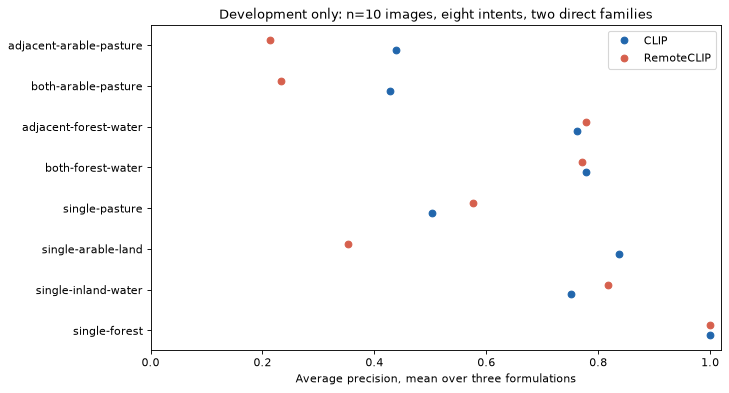

In [11]:
development_result = evaluate_development(ROOT, bootstrap=True)
assert development_result["stage"] == "development-integration-only"
assert not development_result["test_model_evaluation"]
assert not development_result["new_encoding"]
main = development_result["main"]
intent_scores = pd.DataFrame(main["intents"])
paired_scores = pd.DataFrame(main["paired_intents"])
display(
    pd.DataFrame(main["reference_coverage"])[
        ["intent_id", "candidate_count", "known_positive_count", "unknown_count"]
    ]
)
display(paired_scores[["intent_id", "metric", "status", "value"]].round(4))
fig, ax = plt.subplots(figsize=(9, 4.8), constrained_layout=True)
intent_ids = [i["intent_id"] for i in queries["intents"]]
for offset, model in zip([-0.12, 0.12], MODEL_NAMES, strict=True):
    points = (
        intent_scores.query("metric == 'average_precision'")
        .set_index(["model_id", "intent_id"])
        .loc[model]
        .loc[intent_ids]
    )
    ax.plot(
        points.value,
        [i + offset for i in range(8)],
        "o",
        color=MODEL_COLORS[model],
        label=MODEL_NAMES[model],
    )
ax.set_yticks(range(8), intent_ids)
ax.set_xlim(0, 1.02)
ax.set_xlabel("Average precision, mean over three formulations")
ax.set_title("Development only: n=10 images, eight intents, two direct families")
ax.legend()
fig.savefig(ROOT / "outputs/evaluation-development-v3/intent_ap.png", dpi=130)
plt.show()

### 9.1 Interpretation of this Development integration

P@10 differences are zero because every complete top ten contains the same ten
candidates. The descriptive RemoteCLIP-minus-CLIP AP mean is about **−0.0940**;
this is a technical pilot observation, not evidence of general model superiority.
The plot includes dependent single/conjunction/adjacency intents, not independent
replicates. Original labels and ranking bytes remain unchanged.

## 10. How do wording, ranking stability and exploratory controls differ?

The quality range compares metric values across formulations under shared
reference assignments. Top-ten Jaccard instead measures ID-set overlap and does
not depend on reference judgments. In this ten-candidate integration Jaccard is
necessarily one even when formulation AP varies: set stability is not quality.

Both-present relation controls remain separate exploratory collections. On this
Development pilot they contain six and two true cases, no false cases and only
one spatial group. P@10 is undefined below ten candidates; AP=1 in an all-positive
control is uninformative. Neither control isolates relation capability. Unknown
references and unresolved error patterns remain explicit; manual visual/map
disagreements are separate qualitative annotations.

In [12]:
display(
    pd.DataFrame(main["quality_variation"])
    .query("metric == 'average_precision'")[
        ["model_id", "intent_id", "status", "value"]
    ]
    .round(4)
)
jaccard = pd.DataFrame(main["top_k_jaccard"])
display(
    jaccard.groupby("model_id").agg(
        pairs=("jaccard", "size"), mean_jaccard=("jaccard", "mean")
    )
)
display(
    pd.DataFrame(
        [
            {
                "intent": c["intent_id"],
                **c["reference_counts"],
                "groups": c["spatial_groups"],
                "role": c["role"],
            }
            for c in development_result["exploratory_controls"]
        ]
    )
)
errors = pd.DataFrame(main["error_samples"])
display(errors.groupby(["model_id", "category"]).size().rename("sampled ranks"))
print("Prescribed p1 ranks 1/5/10; repeated patch IDs remain explicit in result JSON.")

,model_id,intent_id,status,value
1,clip-openai-vit-b32,single-forest,exact,0.0000
3,remoteclip-vit-b32,single-forest,exact,0.0000
5,clip-openai-vit-b32,single-inland-water,exact,0.1806
7,remoteclip-vit-b32,single-inland-water,exact,0.2306
9,clip-openai-vit-b32,single-arable-land,exact,0.0571
11,remoteclip-vit-b32,single-arable-land,exact,0.0611
13,clip-openai-vit-b32,single-pasture,exact,0.0676
15,remoteclip-vit-b32,single-pasture,exact,0.0500
17,clip-openai-vit-b32,both-forest-water,exact,0.0935
19,remoteclip-vit-b32,both-forest-water,exact,0.1012


,pairs,mean_jaccard
model_id,,
clip-openai-vit-b32,24,1.0
remoteclip-vit-b32,24,1.0


,intent,true,false,unknown,groups,role
0,adjacent-forest-water,6,0,0,1,exploratory
1,adjacent-arable-pasture,2,0,0,1,exploratory


model_id             category               
clip-openai-vit-b32  class-a-only                6
                     class-b-only                2
                     neither                     1
                     satisfied                   7
                     single-presence-failure     8
remoteclip-vit-b32   class-a-only                3
                     class-b-only                3
                     neither                     3
                     satisfied                  10
                     single-presence-failure     5
Name: sampled ranks, dtype: int64

Prescribed p1 ranks 1/5/10; repeated patch IDs remain explicit in result JSON.


## 11. What can two-family resampling tell us?

The primary results above are paired per-intent values and descriptive means.
The optional frozen family resampling keeps all dependent intents/formulations
and both models together, including repeated family multiplicities. Equal-intent
weighting is preserved within each draw. With two families drawn twice, there
are only three family multiplicity combinations; 10,000 draws do not create
independent evidence.

The following is **restricted sensitivity**, not a confidence interval or a
model-superiority test. Lower/upper reference-envelope endpoint distributions
are kept separate from resampling variation. They coincide here because every
Development reference is judged. Wording variation remains a third quantity.

In [13]:
sensitivity = development_result["family_sensitivity"]
display(
    pd.DataFrame(sensitivity["results"])[
        [
            "metric",
            "status",
            "lower_reference_envelope_percentiles",
            "upper_reference_envelope_percentiles",
        ]
    ]
)
ap_sensitivity = next(
    r for r in sensitivity["results"] if r["metric"] == "average_precision"
)
display(pd.DataFrame(ap_sensitivity["multiplicity_estimates"]))
print("Confidence interval claim:", sensitivity["confidence_interval"])
print("Result artifact:", development_result["version"])
print("Saved local results.json with benchmark/model/source/analysis provenance.")

,metric,status,lower_reference_envelope_percentiles,upper_reference_envelope_percentiles
0,p_at_10,restricted-sensitivity-diagnostic,"[0.0, 0.0]","[0.0, 0.0]"
1,average_precision,restricted-sensitivity-diagnostic,"[-0.2071031746031746, 0.01909722222222221]","[-0.2071031746031746, 0.01909722222222221]"


,family_counts,intent_occurrences,lower_reference_envelope,upper_reference_envelope
0,"{'arable-pasture': 2, 'forest-water': 0}",8,-0.207103,-0.207103
1,"{'arable-pasture': 1, 'forest-water': 1}",8,-0.094003,-0.094003
2,"{'arable-pasture': 0, 'forest-water': 2}",8,0.019097,0.019097


Confidence interval claim: False
Result artifact: evaluation-development-v3
Saved local results.json with benchmark/model/source/analysis provenance.


## 12. Findings, limitations and next stage

The pipeline converts complete stored rankings into formulation and intent
scores, exact shared-completion paired bounds, quality ranges, top-k Jaccard,
error categories, descriptive aggregate envelopes and separate exploratory
controls. Controlled examples verify variable AP denominators and completion
coupling; actual integration covers ten Development images without new encoding
or downloads. Reference bounds, wording variation and restricted resampling
are distinct in the artifact schema.

The general estimand remains generalized-map agreement. Sparse relation negatives,
only two direct intent families and possible loose cross-intent envelopes limit
interpretation. The documented known-negative/unknown-class-pattern taxonomy
edge is explicitly unresolved and absent from the frozen inventory.

Reusable metric kernels remain in `retrieval`; paired analysis/diagnostics live
in `evaluation`, stored-data/provenance integration in `evaluation_run`. Compact
examples, tables and figures stay in this notebook. Review 2 must examine the
implemented contracts before human merge; WP6 alone may initiate the final
Test model evaluation. No final Test embeddings or rankings have been produced.